# Week 2 practical: Data preprocessing — lecturer solutions
**CHS2406: Data Driven AI · Dr Hamid Nasiri · 60 minutes**

This practical accompanies **Week02_Lecture01_Data Pre-processing_PartA**.
You will inspect a dataset, correct documented data problems, encode categories,
handle missing values without leaking test information, and interpret correlation.

**How to work:** select the Python 3 kernel and run cells from top to bottom with
**Shift + Enter**. Read the explanation, run the worked example, then complete the
short exercise. Replace each `None` beside `TODO` with your answer. The exercises
provide feedback and do not block later examples when left unfinished.

Work through **sections 0–6 during the hour**. Stop at the clearly marked end
of the core practical. Extensions A–F are for later study or students who finish early.

| Section | Time | Activity | Related lecture slides |
| --- | --- | --- | --- |
| 0 | 0–5 min | Setup and dataset | — |
| 1 | 5–13 min | Inspect data and identify problems | 4–13, 43–46 |
| 2 | 13–23 min | Clean documented errors | 19–23 |
| 3 | 23–31 min | Encode nominal and ordinal data | 6–9 |
| 4 | 31–43 min | Split data and impute safely | 23–25 |
| 5 | 43–55 min | Interpret Pearson correlation | 39–42 |
| 6 | 55–60 min | Exit questions | Review |

**You need:** basic Python variables, lists and indexing; Python 3.10 or later;
NumPy, pandas, Matplotlib, SciPy and scikit-learn. No GPU, data download or account
is required. The data is generated inside this notebook. Install packages before
the session if your environment does not already provide them.

**Lecturer copy:** exercises are completed, with answer notes and delivery guidance.


## 0. Setup and dataset · 5 minutes

The dataset describes **80 fictional students**, plus two accidentally repeated
records. It is deliberately imperfect. It contains no real student information.
Scores are generated partly from study hours and attendance so that we can
practise interpreting relationships. These patterns are teaching examples.

| Column | Meaning | Conceptual type |
| --- | --- | --- |
| `student_id` | Identifier, even though stored as an integer | Nominal label |
| `age` | Recorded age in whole years | Numerical, recorded as discrete |
| `study_hours` | Weekly hours of study | Numerical, continuous |
| `attendance` | Percentage of sessions attended | Numerical |
| `transport` | Bus, Train, Car or Walk | Nominal |
| `satisfaction` | Low, Medium or High | Ordinal |
| `height_cm`, `arm_span_cm` | Measurements in centimetres | Numerical, ratio |
| `quiz_score` | Quiz score out of 100 | Numerical target for a prediction task |

**Dataset codebook:** `-99` means missing in `study_hours` and `attendance`.
The permitted ranges in this fictional dataset are age 16–100 years, study hours
0–60 per week, and attendance 0–100%. These are supplied rules, not thresholds
estimated from the data. A value outside a permitted range needs investigation.


In [1]:
# If required, uncomment the next line, run it, then restart the kernel.
# %pip install numpy pandas matplotlib scipy scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Ready. pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)


Ready. pandas: 2.2.3 | scikit-learn: 1.8.0


In [2]:
# Worked example: a fixed seed makes the data reproducible.
rng = np.random.default_rng(42)
n_students = 80
hours = np.round(rng.uniform(1, 14, n_students), 1)
attendance = np.round(rng.uniform(55, 100, n_students), 1)
height = np.round(rng.normal(170, 8, n_students), 1)
score = np.clip(12 + 4 * hours + 0.28 * attendance
                + rng.normal(0, 7, n_students), 0, 100).round(1)

raw = pd.DataFrame({
    'student_id': np.arange(1001, 1001 + n_students),
    'age': rng.integers(18, 31, n_students).astype(float),
    'study_hours': hours,
    'attendance': attendance,
    'transport': rng.choice(['Bus', 'Train', 'Car', 'Walk'], n_students),
    'satisfaction': rng.choice(['Low', 'Medium', 'High'], n_students),
    'height_cm': height,
    'arm_span_cm': np.round(height + rng.normal(0, 2, n_students), 1),
    'quiz_score': score,
})

# Insert problems deliberately. The later cleaning rules use the codebook.
raw.loc[[2, 11, 29, 53, 70], 'study_hours'] = np.nan
raw.loc[7, 'study_hours'] = -3
raw.loc[9, 'study_hours'] = -99
raw.loc[17, 'attendance'] = 140
raw.loc[22, 'attendance'] = -99
raw.loc[12, 'age'] = 250
raw.loc[3, 'transport'] = ' bus '
raw.loc[4, 'transport'] = 'BUS'
raw.loc[5, 'transport'] = 'Bus '
raw.loc[6, 'satisfaction'] = ' HIGH '
raw = pd.concat([raw, raw.iloc[[0, 1]]], ignore_index=True)

display(raw.head(10))


,student_id,age,study_hours,attendance,transport,satisfaction,height_cm,arm_span_cm,quiz_score
0,1001,18.0,11.1,84.9,Car,Medium,177.9,175.8,79.0
1,1002,21.0,6.7,73.3,Walk,High,166.0,166.9,51.9
2,1003,20.0,NaN,91.6,Walk,Low,160.5,160.2,82.7
3,1004,27.0,10.1,62.5,bus,Medium,162.3,158.6,63.8
4,1005,18.0,2.2,56.0,BUS,Low,164.2,166.1,35.8
5,1006,20.0,13.7,59.1,Bus,Medium,187.0,185.8,71.0
6,1007,25.0,10.9,87.5,Walk,HIGH,163.4,162.3,69.8
7,1008,27.0,-3.0,75.8,Train,Low,176.7,174.6,92.9
8,1009,24.0,2.7,62.3,Car,High,162.8,161.5,31.2
9,1010,29.0,-99.0,77.5,Train,High,177.5,178.4,53.6


## 1. Inspect the dataset · 8 minutes

Start by finding out what each column means and how it is stored.
`shape` gives the number of rows and columns. `info()` reports column types and
non-null counts. `describe()` summarises numerical columns. `isna()` identifies
recognised missing values. **A storage type is not the same as a conceptual type:**
an integer student identifier is still a label.

**Before running:** will pandas count `-99` as missing automatically?


In [3]:
print('Rows and columns:', raw.shape)
raw.info()
display(raw.describe())
display(raw.isna().sum().rename('Recognised missing values').to_frame())
display(raw['transport'].value_counts(dropna=False).rename('Number of records'))


Rows and columns: (82, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   student_id    82 non-null     int64  
 1   age           82 non-null     float64
 2   study_hours   77 non-null     float64
 3   attendance    82 non-null     float64
 4   transport     82 non-null     object 
 5   satisfaction  82 non-null     object 
 6   height_cm     82 non-null     float64
 7   arm_span_cm   82 non-null     float64
 8   quiz_score    82 non-null     float64
dtypes: float64(6), int64(1), object(2)
memory usage: 5.9+ KB


,student_id,age,study_hours,attendance,height_cm,arm_span_cm,quiz_score
count,82.000,82.000,77.000,82.000,82.000,82.000,82.000
mean,1039.549,26.927,5.925,75.335,170.006,169.972,64.034
std,23.734,25.228,12.655,24.006,7.818,8.106,15.802
min,1001.000,18.000,-99.000,-99.000,152.800,151.300,31.200
25%,1019.250,20.000,4.000,67.075,164.250,165.000,52.100
50%,1039.500,25.000,7.100,76.800,169.350,169.450,63.200
75%,1059.750,27.000,10.700,86.450,174.900,175.350,77.975
max,1080.000,250.000,13.700,140.000,190.100,187.700,100.000


,Recognised missing values
student_id,0
age,0
study_hours,5
attendance,0
transport,0
satisfaction,0
height_cm,0
arm_span_cm,0
quiz_score,0


transport
Walk     22
Train    20
Car      19
Bus      18
 bus      1
Bus       1
BUS       1
Name: Number of records, dtype: int64

### Exercise 1 · Audit the data
Complete the two expressions below. Count exact duplicate rows and recognised
missing values in `study_hours`. Then explain to your neighbour why `-99` is
absent from the missing-value count.

<details><summary>Hint</summary>
`duplicated()` and `isna()` return Boolean values. Use `.sum()` to count True values.
</details>


In [4]:
n_duplicate_rows = raw.duplicated().sum()
n_missing_hours = raw['study_hours'].isna().sum()
assert n_duplicate_rows == 2 and n_missing_hours == 5
print('Correct. Duplicates:', n_duplicate_rows,
      '| Recognised missing study-hour values:', n_missing_hours)


Correct. Duplicates: 2 | Recognised missing study-hour values: 5


**Lecturer answer / discussion:** 
    There are two exact duplicate rows and five recognised missing study-hour values.
    The placeholder `-99` and the invalid value `-3` are numbers, so pandas does not
    treat them as missing until we apply documented cleaning rules.


## 2. Clean documented errors · 10 minutes

Keep the original data in `raw` and work on a copy. Remove exact accidental
duplicates, standardise category labels, replace confirmed missing placeholders,
and mark invalid measurements as missing. For this exercise, assume we checked
the invalid measurements with the source and could not recover their true values.

These operations use fixed rules from the codebook. We will learn replacement
means **after splitting**, using training data only. Do not discard a valid
unusual observation merely because it looks different.


In [5]:
clean = raw.drop_duplicates().copy()
clean['transport'] = clean['transport'].str.strip().str.title()
clean['satisfaction'] = clean['satisfaction'].str.strip().str.title()

# -99 is a confirmed missing-value code for these two columns only.
placeholder_columns = ['study_hours', 'attendance']
clean[placeholder_columns] = clean[placeholder_columns].replace(-99, np.nan)

permitted_ranges = {'age': (16, 100), 'study_hours': (0, 60),
                    'attendance': (0, 100)}
for column, (minimum, maximum) in permitted_ranges.items():
    invalid = clean[column].notna() & ~clean[column].between(minimum, maximum)
    clean.loc[invalid, column] = np.nan

print('Rows before:', len(raw), '| Rows after removing duplicates:', len(clean))
display(clean[['age', 'study_hours', 'attendance']].isna().sum().to_frame('Missing after cleaning'))
display(clean['transport'].value_counts().rename('Standardised transport labels'))


Rows before: 82 | Rows after removing duplicates: 80


,Missing after cleaning
age,1
study_hours,7
attendance,2


transport
Walk     21
Bus      21
Train    20
Car      18
Name: Standardised transport labels, dtype: int64

### Exercise 2 · Apply a range rule to new measurements
A new batch contains attendance percentages `[72, 101, -5, missing, 89]`.
Replace values outside 0–100 with `NaN`, while retaining valid values and the
existing missing value. Write one pandas expression.

<details><summary>Hint</summary>
`series.between(0, 100)` identifies valid values. `series.mask(condition, np.nan)`
replaces values where the condition is True. `~` reverses a Boolean condition.
</details>


In [6]:
new_attendance = pd.Series([72, 101, -5, np.nan, 89], name='attendance')
attendance_checked = new_attendance.mask(~new_attendance.between(0, 100), np.nan)
assert np.allclose(attendance_checked, [72, np.nan, np.nan, np.nan, 89], equal_nan=True)
display(attendance_checked)
print('Correct: retain valid measurements and mark invalid ones as missing.')


Correct: retain valid measurements and mark invalid ones as missing.


0    72.0
1     NaN
2     NaN
3     NaN
4    89.0
Name: attendance, dtype: float64

**Lecturer answer / discussion:** 
    The result is `[72, NaN, NaN, NaN, 89]`. The range rule comes from the codebook.
    In a real application, record the reason for each correction and investigate
    the source before deciding that a suspicious measurement is invalid.


## 3. Encode categories · 8 minutes

**Nominal:** Bus, Train, Car and Walk have no natural rank. Using arbitrary codes
as numerical features can impose artificial distances in a model such as k-NN.
One-hot encoding creates a separate indicator column for each category.

**Ordinal:** satisfaction has a declared order, Low < Medium < High. We can
encode that order explicitly. Codes 0, 1 and 2 do not establish that the real
difference between adjacent levels is equal.

The next cell is a small encoding demonstration. In a prediction workflow,
fit an encoder on training data and reuse it for validation/test data.


In [7]:
toy_categories = pd.DataFrame({
    'transport': ['Bus', 'Train', 'Car', 'Walk'],
    'satisfaction': ['Low', 'Medium', 'High', 'Medium']
})
display(pd.get_dummies(toy_categories['transport'], prefix='transport', dtype=int))

satisfaction_order = {'Low': 0, 'Medium': 1, 'High': 2}
toy_categories['satisfaction_rank'] = toy_categories['satisfaction'].map(satisfaction_order)
display(toy_categories)


,transport_Bus,transport_Car,transport_Train,transport_Walk
0,1,0,0,0
1,0,0,1,0
2,0,1,0,0
3,0,0,0,1


,transport,satisfaction,satisfaction_rank
0,Bus,Low,0
1,Train,Medium,1
2,Car,High,2
3,Walk,Medium,1


### Exercise 3 · One-hot encode the cleaned transport column
Create four transport indicator columns using `pd.get_dummies`, with the prefix
`transport` and integer output. Then answer: does Bus = 0, Train = 1, Car = 2
imply that a car is twice as far from a bus as a train is?

<details><summary>Hint</summary>
Follow the worked example, replacing the toy Series with `clean['transport']`.
</details>


In [8]:
transport_encoded = pd.get_dummies(clean['transport'], prefix='transport', dtype=int)
assert transport_encoded.shape == (80, 4)
assert (transport_encoded.sum(axis=1) == 1).all()
display(transport_encoded.head())
print('Correct: four indicator columns, with one active category per row.')


Correct: four indicator columns, with one active category per row.


,transport_Bus,transport_Car,transport_Train,transport_Walk
0,0,1,0,0
1,0,0,0,1
2,0,0,0,1
3,1,0,0,0
4,1,0,0,0


**Lecturer answer / discussion:** 
    The four columns are `transport_Bus`, `transport_Car`, `transport_Train` and
    `transport_Walk`. Numerical codes impose distances but transport labels do not
    justify those distances. For satisfaction, the order is meaningful, but equal
    numerical gaps remain a modelling assumption.


## 4. Split data and handle missing values safely · 12 minutes

Suppose we want to predict `quiz_score`. The identifier is not a useful
measurement, so we exclude it from the input features.

Split the 80 unique records into **80% training, 10% validation and 10% test**.
Training learns parameters. Validation supports model choices. Keep the test
set for a final assessment after the choices are fixed.

Use `fit_transform` on training data and `transform` on validation/test data.
This rule applies to learned imputation, scaling, encoders and PCA. The fixed
cleaning rules above do not calculate statistics from held-out observations.


In [9]:
X = clean.drop(columns=['student_id', 'quiz_score'])
y = clean['quiz_score']

# First hold out 20%; split that equally into validation and test.
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.20, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.50, random_state=42)

print('Training:', len(X_train), '| Validation:', len(X_val), '| Test:', len(X_test))
print('The same student never appears in more than one split.')


Training: 64 | Validation: 8 | Test: 8
The same student never appears in more than one split.


In [10]:
numeric_columns = ['age', 'study_hours', 'attendance', 'height_cm', 'arm_span_cm']
imputer = SimpleImputer(strategy='mean')

train_ready = X_train.copy()
val_ready = X_val.copy()
test_ready = X_test.copy()
train_ready[numeric_columns] = imputer.fit_transform(X_train[numeric_columns])
val_ready[numeric_columns] = imputer.transform(X_val[numeric_columns])
test_ready[numeric_columns] = imputer.transform(X_test[numeric_columns])

display(pd.Series(imputer.statistics_, index=numeric_columns,
                  name='Mean learned from training only').to_frame())
missing_rows = X_train['study_hours'].isna()
print('Training rows whose study hours were imputed:')
display(pd.DataFrame({'Before': X_train.loc[missing_rows, 'study_hours'],
                      'After': train_ready.loc[missing_rows, 'study_hours']}))
print('Remaining numerical missing values:',
      sum(frame[numeric_columns].isna().sum().sum()
          for frame in [train_ready, val_ready, test_ready]))


Training rows whose study hours were imputed:
Remaining numerical missing values: 0


,Mean learned from training only
age,24.297
study_hours,7.400
attendance,77.184
height_cm,169.597
arm_span_cm,169.520


,Before,After
9,NaN,7.4
7,NaN,7.4
53,NaN,7.4
11,NaN,7.4
29,NaN,7.4
2,NaN,7.4


**Why mean imputation is a starting point:** it is simple and follows the lecture
example, but it reduces variability and can be affected by extreme values.
A median can be more suitable for a strongly skewed numerical feature. Missing
values in categories need a categorical strategy, such as an explicit Unknown
category. Our cleaned transport and satisfaction columns have no missing values.

The next small example isolates the leakage problem. We do not train a model
on it. Predict the correct replacement before running your code.


### Exercise 4 · Reuse a training mean
Training values are `[10, 20, missing]`. Test values are `[90, missing]`.
Calculate the observed **training** mean and use it to fill the test missing
value. Do not include the observed test value in the mean.

<details><summary>Hint</summary>
`Series.mean()` ignores NaN by default. Use `.fillna(training_mean)` on the test Series.
</details>


In [11]:
mini_train = pd.Series([10, 20, np.nan], name='Training')
mini_test = pd.Series([90, np.nan], name='Test')
training_mean = mini_train.mean()
mini_test_filled = mini_test.fillna(training_mean)
assert np.isclose(training_mean, 15)
assert np.allclose(mini_test_filled, [90, 15])
print('Correct. Training mean:', training_mean)
display(mini_test_filled)


Correct. Training mean: 15.0


0    90.0
1    15.0
Name: Test, dtype: float64

**Lecturer answer / discussion:** 
    The training mean is 15, so the test values become `[90, 15]`. Combining observed
    training and test values would give 40. That allows a held-out observation to
    influence the training preprocessing. Fitting a separate mean on the test
    data is also incorrect. Reuse the same learned transformation.


## 5. Pearson correlation and plots · 12 minutes

Use the **training data** for exploration that may guide feature/model choices.
The coefficient `r` measures the direction and strength of a **linear**
relationship. Values near +1 or −1 indicate stronger linear association.
The magnitude matters: −0.9 is stronger than +0.2.

We calculate correlations with pandas, plot a scatter plot and display a heatmap.
Exclude the identifier and avoid treating arbitrary category codes as measurements.
Correlation alone does not establish causation.


,Pearson r with quiz score
age,-0.177
study_hours,0.751
attendance,0.335
height_cm,0.071
arm_span_cm,0.108


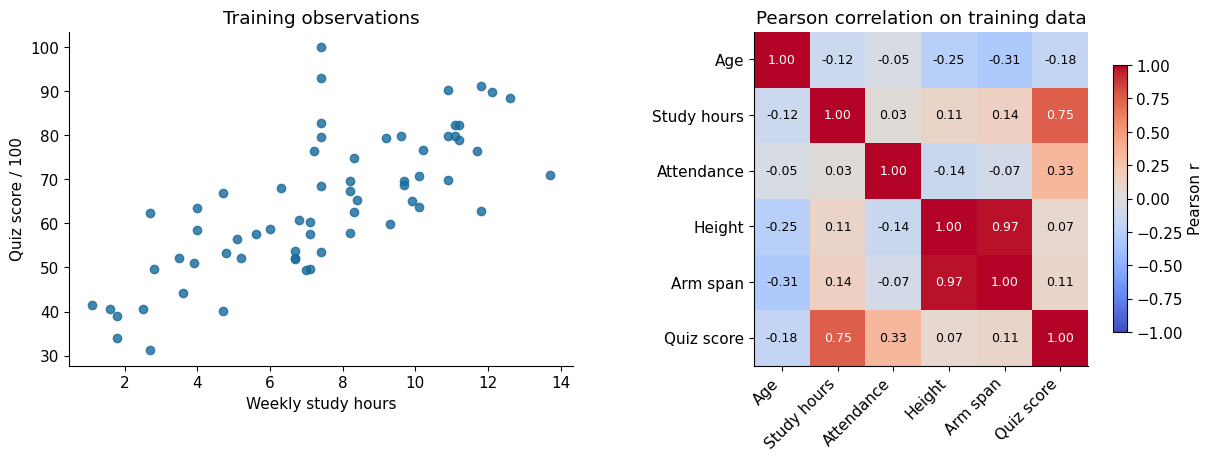

In [12]:
training_numeric = train_ready[numeric_columns].copy()
training_numeric['quiz_score'] = y_train
correlation = training_numeric.corr(method='pearson')
target_correlations = correlation['quiz_score'].drop('quiz_score')
display(target_correlations.rename('Pearson r with quiz score').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].scatter(training_numeric['study_hours'], training_numeric['quiz_score'],
                color='#176b9b', alpha=0.8)
axes[0].set(xlabel='Weekly study hours', ylabel='Quiz score / 100',
            title='Training observations')

image = axes[1].imshow(correlation, vmin=-1, vmax=1, cmap='coolwarm')
labels = ['Age', 'Study hours', 'Attendance', 'Height', 'Arm span', 'Quiz score']
axes[1].set_xticks(range(len(labels)), labels, rotation=45, ha='right')
axes[1].set_yticks(range(len(labels)), labels)
axes[1].set_title('Pearson correlation on training data')
for row in range(len(labels)):
    for column in range(len(labels)):
        value = correlation.iloc[row, column]
        colour = 'white' if abs(value) > 0.6 else 'black'
        axes[1].text(column, row, f'{value:.2f}', ha='center', va='center',
                     color=colour, fontsize=9)
fig.colorbar(image, ax=axes[1], label='Pearson r', shrink=0.8)
plt.show()


### Zero Pearson correlation can hide a nonlinear relationship
For symmetric values of `x`, the relationship `y = x²` can have zero Pearson
correlation even though `x` determines `y` exactly. This is the curved example
on slide 41. **Zero Pearson correlation means no linear correlation. It does
not establish independence or prove that an input is useless for prediction.**

The next plot also shows why we inspect relationships visually. Values imputed
with a mean can change correlations, so treat imputation as a modelling choice.


Pearson r: 0.0


,x,y
0,-2.0,4.0
1,-1.0,1.0
2,0.0,0.0
3,1.0,1.0
4,2.0,4.0


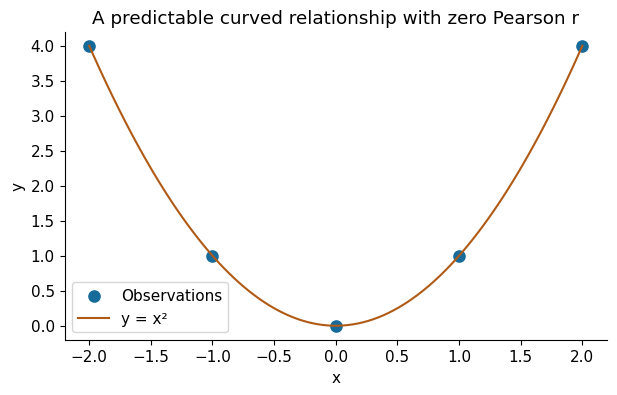

In [13]:
x_curve = np.array([-2, -1, 0, 1, 2], dtype=float)
y_curve = x_curve ** 2
curve_data = pd.DataFrame({'x': x_curve, 'y': y_curve})
print('Pearson r:', round(curve_data['x'].corr(curve_data['y']), 6))
display(curve_data)
plt.scatter(x_curve, y_curve, s=65, color='#176b9b', label='Observations')
grid = np.linspace(-2, 2, 100)
plt.plot(grid, grid ** 2, color='#b05a16', label='y = x²')
plt.xlabel('x')
plt.ylabel('y')
plt.title('A predictable curved relationship with zero Pearson r')
plt.legend()
plt.show()


### Exercise 5 · Test the same idea on new values
Use `x = [-3, -2, -1, 0, 1, 2, 3]` and `y = x²`. Calculate Pearson correlation,
then calculate the exact value of `y` at `x = 3`. Would you discard this input
solely because its Pearson correlation is zero?

<details><summary>Hint</summary>
Construct `pd.Series(x_challenge)` and call `.corr(pd.Series(y_challenge))`.
Python uses `**` for powers.
</details>


In [14]:
x_challenge = np.arange(-3, 4, dtype=float)
y_challenge = x_challenge ** 2
challenge_r = pd.Series(x_challenge).corr(pd.Series(y_challenge))
prediction_at_three = 3 ** 2
assert np.isclose(challenge_r, 0, atol=1e-12) and prediction_at_three == 9
print('Correct. Pearson r:', challenge_r, '| y when x = 3:', prediction_at_three)
print('The deterministic curved relationship still supports exact prediction.')


Correct. Pearson r: 0.0 | y when x = 3: 9
The deterministic curved relationship still supports exact prediction.


**Lecturer answer / discussion:** 
    Pearson correlation is zero and the prediction is 9. The input determines the
    target through a nonlinear rule. A zero Pearson coefficient cannot justify
    removing a feature by itself. This reinforces the correction to the wording
    on lecture slide 39 and the correct nonlinear illustration on slide 41.


## 6. Exit questions · 5 minutes

Write a sentence for each question, then compare your answers with a neighbour.

1. Why is `student_id` a nominal label even when pandas stores it as an integer?
2. Why do we learn an imputation mean from training data only?
3. What can Pearson correlation of zero tell us, and what can it not tell us?
4. If clustering labels a reading as noise, what should we investigate before deleting it?

**Your answers**

1. ...
2. ...
3. ...
4. ...

Save your notebook with your completed code and explanations.

---
# End of the 60-minute practical
**Stop here during the scheduled session.** Everything below is optional.


**Lecturer exit answers:**
1. An identifier labels a student. Its numerical gaps do not measure a meaningful property.
2. Held-out observations must not influence learned training parameters. Apply the same training mean to all splits.
3. Zero Pearson correlation indicates no linear correlation in the observations. Nonlinear dependence may remain.
4. Check the source, units, sensor condition and domain context. A rare genuine event may be valuable.

**Delivery notes:** prepare the Python environment before class. Keep the dataset
generation cell provided, so students can focus on preprocessing. If the class
falls behind, demonstrate Exercise 3 and prioritise Exercise 4. Use the Vevox
questions on encoding, imputation, outliers and zero correlation at the matching
points. Do not attempt all extensions during this hour.


# Optional extensions
These short examples cover the remaining implementation topics in Part A.
Complete the core sections first, then choose an extension that interests you.
All datasets are generated or embedded. Each extension explains how its results
should be interpreted.

| Extension | Topic | Slides |
| --- | --- | --- |
| A | Binning and smoothing | 28–29 |
| B | DBSCAN and HDBSCAN | 30–32 |
| C | Data integration and conflicting units | 35–36 |
| D | Chi-square test for nominal variables | 37–38 |
| E | PCA with training-only fitting | 15–17 |
| F | CatBoost using categorical features | 9 |


## Extension A. Binning and smoothing
Sort the 12 prices from slide 28 and form three equal-frequency bins with four
values each. Replace values with their bin mean, or with the nearest boundary.
The code chooses the lower boundary if distances tie. Smoothing reduces variation
and may hide useful information. In a prediction workflow, define bins and learn
smoothing values from training data, then reuse those definitions.


In [15]:
prices = np.array([4, 8, 13, 15, 21, 21, 22, 24, 25, 28, 33, 34])
bins = np.sort(prices).reshape(3, 4)
bin_means = bins.mean(axis=1, keepdims=True)
smoothed_means = np.repeat(bin_means, 4, axis=1)
lower = bins[:, :1]
upper = bins[:, -1:]
smoothed_boundaries = np.where(bins - lower <= upper - bins, lower, upper)

display(pd.DataFrame({
    'Bin': np.repeat([1, 2, 3], 4),
    'Original price': bins.ravel(),
    'Bin mean': smoothed_means.ravel(),
    'Nearest boundary': smoothed_boundaries.ravel()
}))
print('Three bin means:', bin_means.ravel())


Three bin means: [10. 22. 30.]


,Bin,Original price,Bin mean,Nearest boundary
0,1,4,10.0,4
1,1,8,10.0,4
2,1,13,10.0,15
3,1,15,10.0,15
4,2,21,22.0,21
5,2,21,22.0,21
6,2,22,22.0,21
7,2,24,22.0,24
8,3,25,30.0,25
9,3,28,30.0,25


**Try:** compare what happens to 13 under mean smoothing and boundary smoothing.
Which method retains more distinct values? Neither method is universally better.


## Extension B. Clustering to flag unusual sensor readings
We simulate two operating conditions and a few isolated readings. Temperature
and vibration use different units, so standardise both before measuring distance.
`eps` is the neighbourhood radius in the **standardised feature space**.
`min_samples` controls the local density requirement. DBSCAN uses label `-1`
for noise. That label does not tell us whether a reading is an error or a real fault.

This is a standalone exploratory snapshot, with no held-out prediction evaluation.
Therefore the scaler and clustering fit this snapshot. If clustering-based
decisions become part of a predictive workflow, keep held-out data separate.


-1     4
 0    60
 1    60
Name: Number of readings, dtype: int64

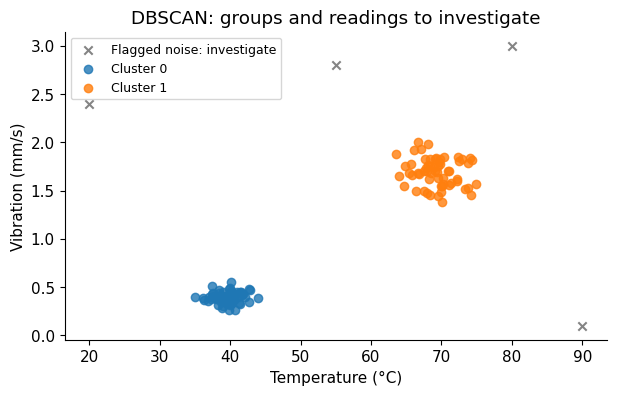

In [16]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

sensor_rng = np.random.default_rng(7)
idle = np.column_stack([sensor_rng.normal(40, 2, 60),
                        sensor_rng.normal(0.4, 0.07, 60)])
running = np.column_stack([sensor_rng.normal(70, 3, 60),
                           sensor_rng.normal(1.7, 0.15, 60)])
unusual = np.array([[20, 2.4], [90, 0.1], [55, 2.8], [80, 3.0]])
sensors = pd.DataFrame(np.vstack([idle, running, unusual]),
                       columns=['temperature_C', 'vibration_mm_s'])
sensors_scaled = StandardScaler().fit_transform(sensors)
db_labels = DBSCAN(eps=0.25, min_samples=6).fit_predict(sensors_scaled)

def plot_sensor_groups(labels, title):
    fig, ax = plt.subplots(figsize=(7, 4))
    for label in np.unique(labels):
        group = sensors.loc[labels == label]
        colour = '#666666' if label == -1 else plt.cm.tab10(int(label) % 10)
        marker = 'x' if label == -1 else 'o'
        name = 'Flagged noise: investigate' if label == -1 else f'Cluster {label}'
        ax.scatter(group['temperature_C'], group['vibration_mm_s'],
                   color=colour, marker=marker, label=name, alpha=0.8)
    ax.set(xlabel='Temperature (°C)', ylabel='Vibration (mm/s)', title=title)
    ax.legend(fontsize=9)
    plt.show()

display(pd.Series(db_labels).value_counts().sort_index().rename('Number of readings'))
plot_sensor_groups(db_labels, 'DBSCAN: groups and readings to investigate')


### HDBSCAN comparison
HDBSCAN examines a hierarchy of density-based clusters and can be useful when
groups have different densities. The example below uses scikit-learn's HDBSCAN
implementation, available from version 1.3. If it is unavailable, this optional
cell prints a message and continues. No extra `hdbscan` package is required.

**Try:** change DBSCAN `eps` to 0.15 or 0.50 and compare the noise count. Explain
why changing a parameter is not evidence that a sensor reading is correct.


/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


-1     2
 0    60
 1    62
Name: Number of readings, dtype: int64

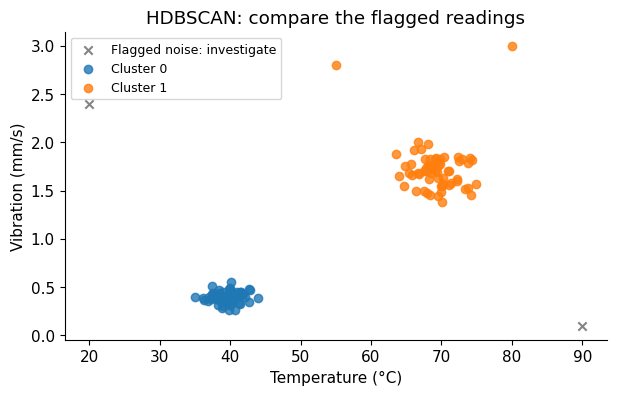

In [17]:
try:
    from sklearn.cluster import HDBSCAN
except ImportError:
    print('HDBSCAN is optional. Use scikit-learn >= 1.3 to run this comparison.')
else:
    hdb_labels = HDBSCAN(min_cluster_size=10, min_samples=6).fit_predict(sensors_scaled)
    display(pd.Series(hdb_labels).value_counts().sort_index().rename('Number of readings'))
    plot_sensor_groups(hdb_labels, 'HDBSCAN: compare the flagged readings')


## Extension C. Integrate sources and flag conflicts
Two systems record height for some of the same students. Their key names and
units differ. Rename the join key, convert metres to centimetres, and use a
left join to retain source A. `validate='one_to_one'` rejects duplicate keys
that could unexpectedly multiply rows. An unmatched record is not zero height.


In [18]:
source_a = pd.DataFrame({'student_id': [101, 102, 103],
                         'height_A_cm': [170, 180, 160]})
source_b = pd.DataFrame({'student_number': [101, 102, 104],
                         'height_B_m': [1.70, 1.82, 1.65]})
source_b = source_b.rename(columns={'student_number': 'student_id'})
source_b['height_B_cm'] = source_b['height_B_m'] * 100

integrated = source_a.merge(source_b[['student_id', 'height_B_cm']],
                             on='student_id', how='left',
                             validate='one_to_one', indicator=True)
integrated['conflict_to_review'] = (
    integrated['height_B_cm'].notna()
    & ~np.isclose(integrated['height_A_cm'], integrated['height_B_cm']))
display(integrated)


,student_id,height_A_cm,height_B_cm,_merge,conflict_to_review
0,101,170,170.0,both,False
1,102,180,182.0,both,True
2,103,160,NaN,left_only,False


**Discuss:** student 102 has conflicting heights after unit conversion, so review
the source and measurement dates. Student 103 has no matching B record. Student
104 appears only in B and a left join does not retain that student. How would an
outer join change the result?


## Extension D. Chi-square association for nominal data
Use the observed counts from lecture slide 38. The null hypothesis is that
science-fiction preference and chess participation are independent in the
population being sampled. Expected counts use row total × column total / grand total.

Set `correction=False` to match the slide's uncorrected Pearson chi-square
calculation. For this demonstration, assume independent observations and check
that expected cell counts are at least 5. A small p-value supplies evidence of
association under the test assumptions. It does not show causation or measure
how strong the association is.


In [19]:
from scipy.stats import chi2_contingency

observed = pd.DataFrame([[250, 200], [50, 1000]],
                        index=['Like science fiction', 'Do not like science fiction'],
                        columns=['Play chess', 'Do not play chess'])
chi_square, p_value, degrees_freedom, expected_counts = chi2_contingency(
    observed.to_numpy(), correction=False)
expected_table = pd.DataFrame(expected_counts, index=observed.index,
                              columns=observed.columns)
print('Observed counts:')
display(observed)
print('Expected counts under independence:')
display(expected_table)
print(f'Chi-square = {chi_square:.3f}, df = {degrees_freedom}, p = {p_value:.3e}')
print('Minimum expected count:', expected_counts.min())
print('Reject independence at alpha = 0.05:', p_value < 0.05)


Observed counts:
Expected counts under independence:
Chi-square = 507.937, df = 1, p = 1.783e-112
Minimum expected count: 90.0
Reject independence at alpha = 0.05: True


,Play chess,Do not play chess
Like science fiction,250,200
Do not like science fiction,50,1000


,Play chess,Do not play chess
Like science fiction,90.0,360.0
Do not like science fiction,210.0,840.0


**Try:** verify the first expected count manually: `450 * 300 / 1500`.
Do not apply Pearson correlation to arbitrary codes for these two nominal variables.


## Extension E. PCA: two measurements to one component
Height and arm span carry overlapping information. Fit scaling and PCA using
training measurements, then reuse both transformations on validation and test
measurements. PCA uses input variation, not target labels. A high explained
variance does not guarantee that a component is useful for predicting a target.


Training shape before: (64, 2) | After: (64, 1)
Variance retained by PC1: 98.5%
Weights on standardised height and arm span: [0.70710678 0.70710678]


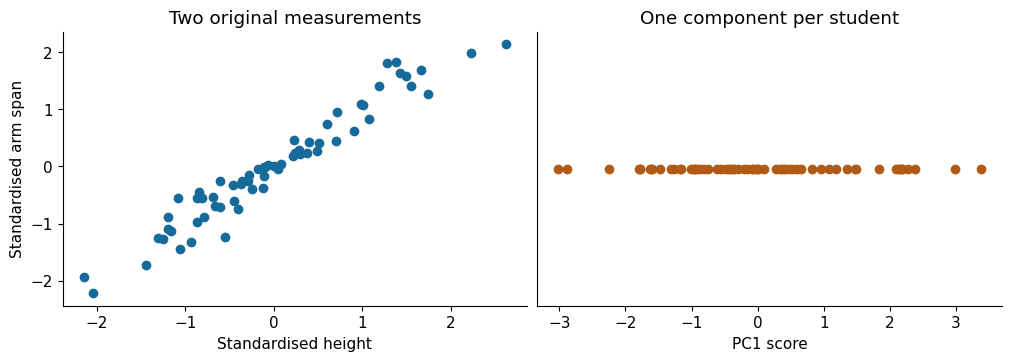

In [20]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

measurement_columns = ['height_cm', 'arm_span_cm']
pca_scaler = StandardScaler()
measurements_train = pca_scaler.fit_transform(train_ready[measurement_columns])
measurements_val = pca_scaler.transform(val_ready[measurement_columns])
measurements_test = pca_scaler.transform(test_ready[measurement_columns])

pca = PCA(n_components=1)
pc_train = pca.fit_transform(measurements_train)
pc_val = pca.transform(measurements_val)
pc_test = pca.transform(measurements_test)
print('Training shape before:', measurements_train.shape, '| After:', pc_train.shape)
print(f'Variance retained by PC1: {100 * pca.explained_variance_ratio_[0]:.1f}%')
print('Weights on standardised height and arm span:', pca.components_[0])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
axes[0].scatter(measurements_train[:, 0], measurements_train[:, 1], color='#176b9b')
axes[0].set(xlabel='Standardised height', ylabel='Standardised arm span',
            title='Two original measurements')
axes[1].scatter(pc_train[:, 0], np.zeros(len(pc_train)), color='#b05a16')
axes[1].set(xlabel='PC1 score', title='One component per student')
axes[1].set_yticks([])
plt.show()


**Try:** change `n_components` to 2 and inspect the explained variance of each
component. What happens to dimensionality? What would you need to check before
choosing one component for a prediction task?


## Extension F. CatBoost with categorical features
This is an optional modelling example linked to slide 9. It requires CatBoost;
it is not needed for the core practical. The cell runs when CatBoost is installed
and otherwise prints a message. To install it, uncomment the installation line
and restart the kernel if your environment requires it.

We define pass as a quiz score of at least 50. The score itself is excluded from
the inputs. CatBoost receives the transport and satisfaction **strings** through
`cat_features`; it does not need our manual one-hot columns. Numerical values
reuse the imputer fitted on training data. Validation supports early stopping,
and the test set supplies one final evaluation. Eight test observations make
this an API demonstration, not a reliable research performance estimate.


In [21]:
# Optional installation, if needed:
# %pip install catboost

try:
    from catboost import CatBoostClassifier
except ImportError:
    print('CatBoost is optional. Install it later if you want to try this extension.')
else:
    from sklearn.metrics import accuracy_score

    model_columns = ['study_hours', 'attendance', 'transport', 'satisfaction']
    y_train_pass = (y_train >= 50).astype(int)
    y_val_pass = (y_val >= 50).astype(int)
    y_test_pass = (y_test >= 50).astype(int)
    cat_model = CatBoostClassifier(iterations=100, depth=3, learning_rate=0.08,
                                   random_seed=42, verbose=False,
                                   allow_writing_files=False, thread_count=2)
    cat_model.fit(train_ready[model_columns], y_train_pass,
                  cat_features=['transport', 'satisfaction'],
                  eval_set=(val_ready[model_columns], y_val_pass),
                  early_stopping_rounds=10)
    predictions = np.asarray(cat_model.predict(test_ready[model_columns])).ravel()
    print('Final toy test accuracy:', round(accuracy_score(y_test_pass, predictions), 3))
    display(pd.DataFrame({'Actual pass': y_test_pass, 'Predicted pass': predictions}))
    print('Use this cell to understand the API; do not tune using the test results.')


Final toy test accuracy: 1.0
Use this cell to understand the API; do not tune using the test results.


,Actual pass,Predicted pass
30,1,1
0,1,1
28,0,0
68,0,0
35,1,1
33,1,1
4,0,0
12,1,1


## Further reading
The lecture deck supplies the topic sequence and examples. These official
references document the APIs used in the notebook:

- [pandas: get_dummies](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html)
- [scikit-learn: avoiding data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [scikit-learn: DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- [scikit-learn: HDBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.HDBSCAN.html)
- [scikit-learn: PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- [SciPy: chi2_contingency](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html)
- [CatBoost: Python examples](https://catboost.ai/docs/en/concepts/python-usages-examples)
